# **Processing and Explanatory Data Analysis project**
## **Project context**
### This project focuses on the in-depth analysis of CAC40 stock market data over a 10-year period, providing a detailed perspective on the evolution of the French market. The dataset used, extracted from Kaggle, contains valuable information on the fluctuations of CAC40 companies' stocks. It includes transaction volumes, which reflect market activity and investor interest, as well as opening and closing prices, and the highest and lowest prices recorded for each stock. This data is available on a daily, monthly, and annual basis, allowing for a multi-scale analysis of market trends and variations. The main objective of this project is to explore this data to identify trends, correlations, and potential predictions on the CAC40 market, thus providing valuable insights for investors and financial analysts.

In [2]:
#Libraries used
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [3]:
data = pd.read_csv("C:/Users/loukm/Desktop/Master 1/Machine Learning/preprocessed_CAC40.csv")
print(data.head(100))

    Unnamed: 0   Name        Date   Open  Closing_Price  Daily_High  \
0            0  Accor  2020-04-03  22.99          23.40       23.40   
1            1  Accor  2020-04-02  23.91          22.99       23.91   
2            2  Accor  2020-04-01  24.10          23.83       24.10   
3            3  Accor  2020-03-31  25.04          25.00       25.24   
4            4  Accor  2020-03-30  26.50          25.02       26.50   
..         ...    ...         ...    ...            ...         ...   
95          95  Accor  2019-11-15  38.14          38.75       38.75   
96          96  Accor  2019-11-14  38.06          38.06       38.06   
97          97  Accor  2019-11-13  38.33          38.33       38.33   
98          98  Accor  2019-11-12  38.69          38.56       38.69   
99          99  Accor  2019-11-11  39.57          39.57       39.57   

    Daily_Low Volume  
0       22.99     67  
1       22.99    250  
2       23.83     37  
3       24.99    336  
4       24.99    415  
..       

## Variables description 
### **Compagnie:** Name of the company listed on the CAC40
### **Date:** Date of the observation (day, month, year)
### **Open_Price:** Opening price of the stock at the specified date
### **Closing_Price:** Closing price of the stock at the specified date
### **Daily_High:** Highest price reached by the stock during the day
### **Daily_Low:** Lowest price reached by the stock during the day
### **Volume:** Number of shares traded during the day

## Cleaning 

In [4]:
#Drop of the column "unnamed"
data = data.drop('Unnamed: 0', axis=1)
#Renaming columns
data = data.rename(columns={'Open': 'Open_Price','Name':'Compagnie'})
print(data.head())

  Compagnie        Date  Open_Price  Closing_Price  Daily_High  Daily_Low  \
0     Accor  2020-04-03       22.99          23.40       23.40      22.99   
1     Accor  2020-04-02       23.91          22.99       23.91      22.99   
2     Accor  2020-04-01       24.10          23.83       24.10      23.83   
3     Accor  2020-03-31       25.04          25.00       25.24      24.99   
4     Accor  2020-03-30       26.50          25.02       26.50      24.99   

  Volume  
0     67  
1    250  
2     37  
3    336  
4    415  


In [5]:
print(data.dtypes)

Compagnie         object
Date              object
Open_Price       float64
Closing_Price    float64
Daily_High       float64
Daily_Low        float64
Volume            object
dtype: object


In [6]:
# Missing values per column
vm = data.isnull().sum()
print(vm)

Compagnie            0
Date                 0
Open_Price         230
Closing_Price        2
Daily_High         204
Daily_Low          204
Volume           20453
dtype: int64


## Here,after observation missing values for variable **Volume** is enough **(20453)** so we decide to impute them by the mean and to drop others for all variables.

In [7]:
#Impute missing values and drop
data['Volume'] = pd.to_numeric(data['Volume'].astype(str).str.replace('NaN', ''), errors='coerce')
data['Volume'].fillna(data['Volume'].mean(),	inplace=True)
data.dropna(subset=data.columns.difference(['Volume']), inplace=True)
print(data.isnull().sum())

Compagnie        0
Date             0
Open_Price       0
Closing_Price    0
Daily_High       0
Daily_Low        0
Volume           0
dtype: int64


C:\Users\loukm\AppData\Local\Temp\ipykernel_17752\495204993.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  data['Volume'].fillna(data['Volume'].mean(),	inplace=True)


## Here,we decide to extract year,month and day to create new variables which weallow us to purchage our analysis

In [8]:
#Conversion of the variables type
data['Compagnie'] = data['Compagnie'].astype(str)
data['Date'] = pd.to_datetime(data['Date'])
# Extraction from "Date" :year, month and day
data['year'] = data['Date'].dt.year
data['month'] = data['Date'].dt.month
data['day'] = data['Date'].dt.day
print(data.head())


  Compagnie       Date  Open_Price  Closing_Price  Daily_High  Daily_Low  \
0     Accor 2020-04-03       22.99          23.40       23.40      22.99   
1     Accor 2020-04-02       23.91          22.99       23.91      22.99   
2     Accor 2020-04-01       24.10          23.83       24.10      23.83   
3     Accor 2020-03-31       25.04          25.00       25.24      24.99   
4     Accor 2020-03-30       26.50          25.02       26.50      24.99   

   Volume  year  month  day  
0    67.0  2020      4    3  
1   250.0  2020      4    2  
2    37.0  2020      4    1  
3   336.0  2020      3   31  
4   415.0  2020      3   30  


## Identifing and Handling Outliers

In [9]:
#Outliers identification using IQR 
Q1	=	data['Open_Price'].quantile(0.25)
Q3	=	data['Open_Price'].quantile(0.75)
IQR	=	Q3	-	Q1
outliers	=	data[(data['Open_Price']	<	Q1	-	1.5	*	IQR)	|	(data['Open_Price']	>	Q3	+	1.5	*	IQR)]
#	Log	Transformation
data['Open_Price']	=	np.log(data['Open_Price']	+	1)

## Data stardization

In [10]:
from sklearn.preprocessing import StandardScaler
import pandas as pd
std = ['Open_Price', 'Closing_Price', 'Daily_High', 'Daily_Low', 'Volume']

for column in std:
    scaler = StandardScaler()
    data[column + '_stand'] = scaler.fit_transform(data[[column]])

print(data.head())

  Compagnie       Date  Open_Price  Closing_Price  Daily_High  Daily_Low  \
0     Accor 2020-04-03    3.177637          23.40       23.40      22.99   
1     Accor 2020-04-02    3.215269          22.99       23.91      22.99   
2     Accor 2020-04-01    3.222868          23.83       24.10      23.83   
3     Accor 2020-03-31    3.259634          25.00       25.24      24.99   
4     Accor 2020-03-30    3.314186          25.02       26.50      24.99   

   Volume  year  month  day  Open_Price_stand  Closing_Price_stand  \
0    67.0  2020      4    3         -0.811522            -0.587182   
1   250.0  2020      4    2         -0.767115            -0.592486   
2    37.0  2020      4    1         -0.758149            -0.581619   
3   336.0  2020      3   31         -0.714764            -0.566481   
4   415.0  2020      3   30         -0.650391            -0.566222   

   Daily_High_stand  Daily_Low_stand  Volume_stand  
0         -0.589187        -0.590250     -1.356504  
1         -0.582

## Exploratory Data Analysis (EDA)

### Variables distribution

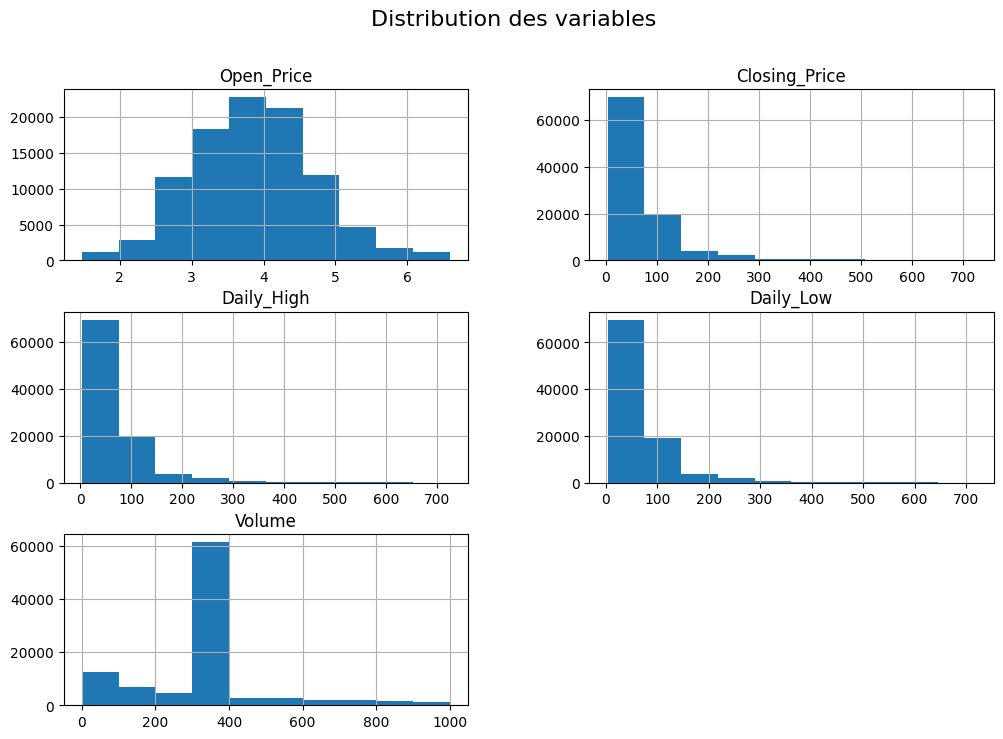

In [11]:
# Histogrammes for all my numerical variables
data[['Open_Price', 'Closing_Price', 'Daily_High', 'Daily_Low', 'Volume']].hist(figsize=(12, 8))
plt.suptitle('Distribution des variables', fontsize=16)
plt.show()

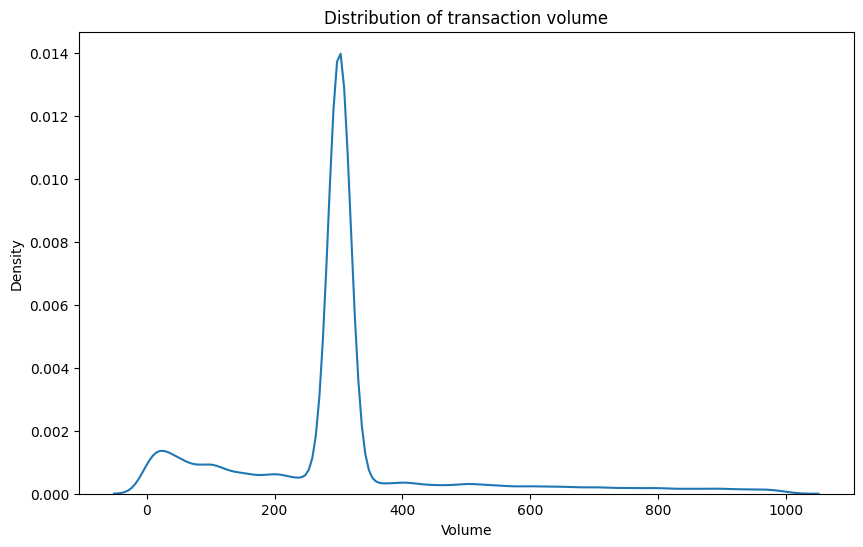

In [12]:
# Kernel Density Estimation (KDE) for my variable volume
plt.figure(figsize=(10, 6))
sns.kdeplot(data['Volume'])
plt.title('Distribution of transaction volume')
plt.xlabel('Volume')
plt.show()

### Correlation between varables

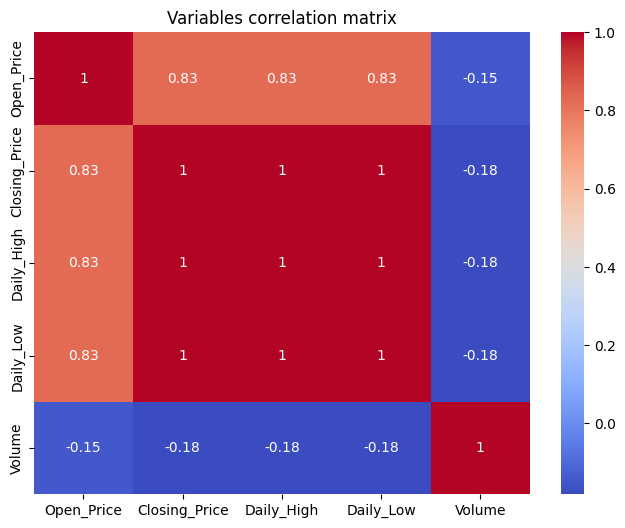

In [13]:
#Heatmap of the correlation matrix
cor_matrix = data[['Open_Price', 'Closing_Price', 'Daily_High', 'Daily_Low', 'Volume']].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(cor_matrix, annot=True, cmap='coolwarm')
plt.title('Variables correlation matrix')
plt.show()

### Prices distribution

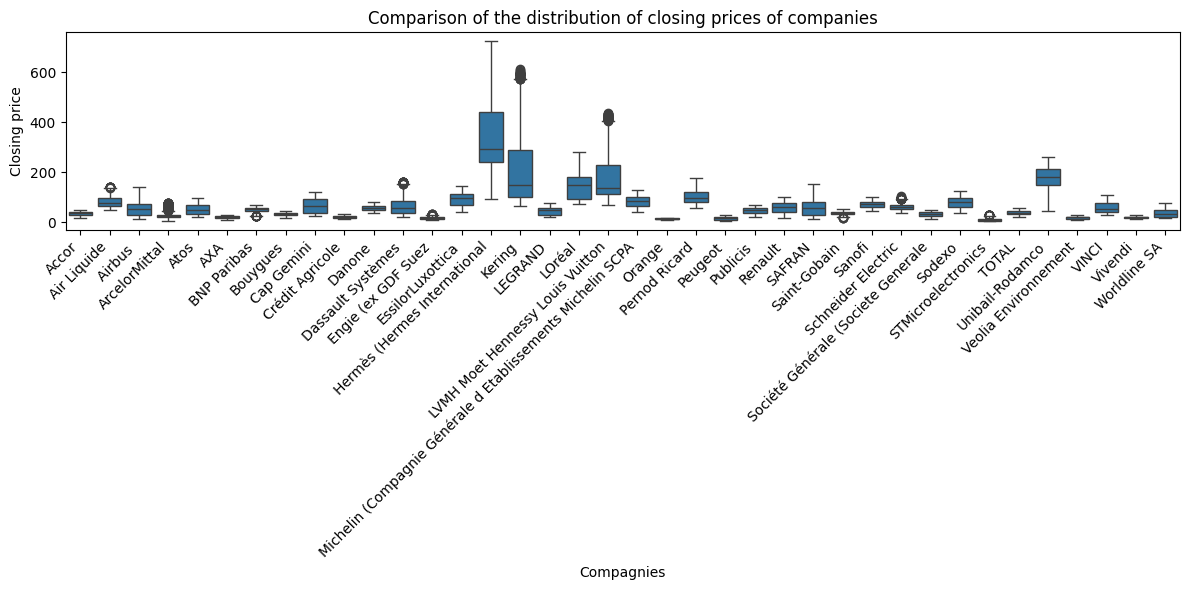

In [14]:
# Boxplots to compare price distribution
plt.figure(figsize=(12, 6))
sns.boxplot(x='Compagnie', y='Closing_Price', data=data)
plt.title('Comparison of the distribution of closing prices of companies')
plt.xticks(rotation=45, ha='right')
plt.xlabel('Compagnies')
plt.ylabel('Closing price')
plt.tight_layout() 
plt.show()

### Visualizing relationships between variables

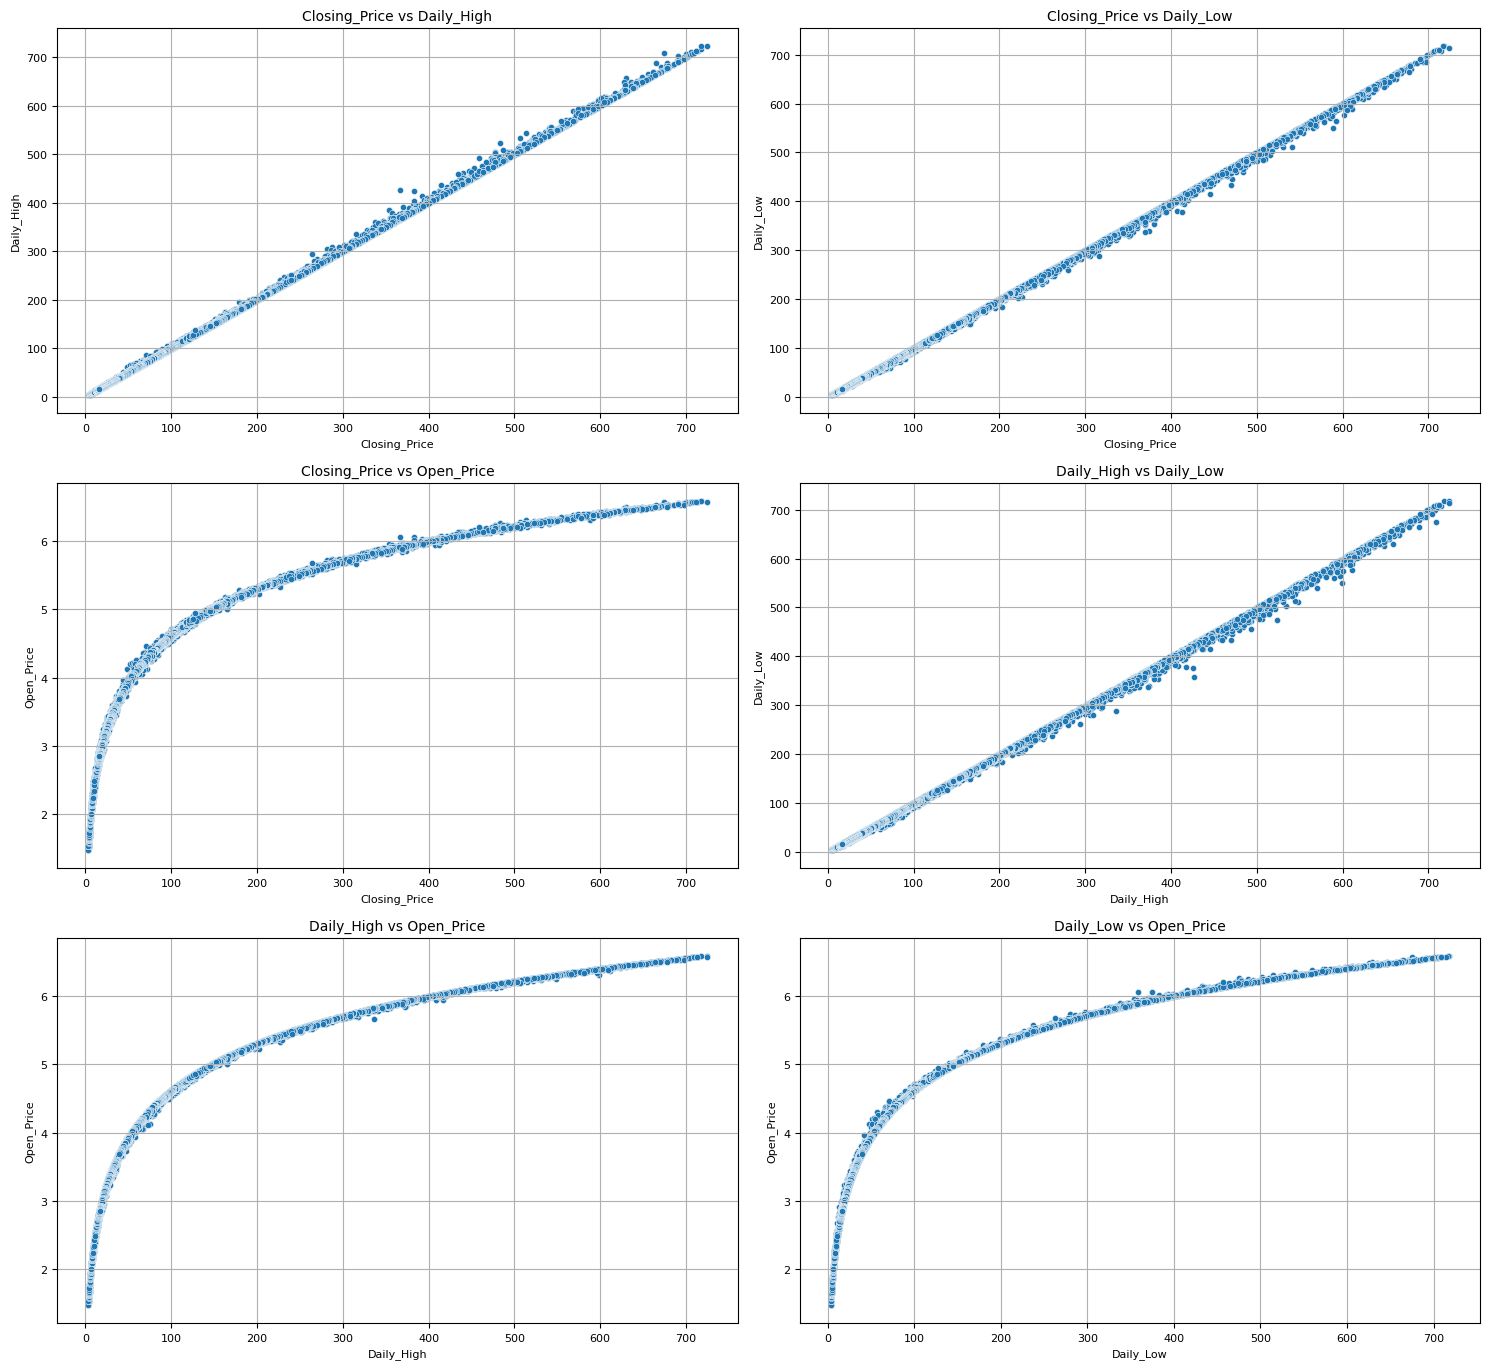

In [15]:
# Columns to exclude
exclude_col = ['year', 'month', 'day', 'Open_Price_stand', 'Closing_Price_stand', 'Daily_High_stand', 'Daily_Low_stand', 'Volume', 'Volume_stand']

# Numeric columns to include (excluding specified columns)
num_col = data.select_dtypes(include=['number']).columns.difference(exclude_col)

# Number of subplots per row
subplots_per_row = 2

# Calculate the number of rows needed
num_rows = (len(num_col) * (len(num_col) - 1) // 2 + subplots_per_row - 1) // subplots_per_row

# Create subplots
fig, axes = plt.subplots(num_rows, subplots_per_row, figsize=(15, 5 * num_rows))  # Adjust figsize as needed

# Initialize subplot counter
subplot_index = 0

# Generate scatter plots
for i in range(len(num_col)):
    for j in range(i + 1, len(num_col)):  # Avoid duplicates and diagonal
        colonne1 = num_col[i]
        colonne2 = num_col[j]

        # Get the appropriate subplot axes
        row_index = subplot_index // subplots_per_row
        col_index = subplot_index % subplots_per_row

        # Handle cases where there are fewer subplots than calculated
        if row_index < num_rows and col_index < subplots_per_row:
            ax = axes[row_index, col_index] if num_rows > 1 else axes[col_index] # handles the case of 1 row

            sns.scatterplot(x=colonne1, y=colonne2, data=data, ax=ax, s=20)  # Reduced marker size (s=20)
            ax.set_title(f'{colonne1} vs {colonne2}', fontsize=10) #Smaller title
            ax.set_xlabel(colonne1, fontsize=8) # Smaller labels
            ax.set_ylabel(colonne2, fontsize=8)
            ax.tick_params(axis='both', which='major', labelsize=8) # Smaller ticks
            ax.grid(True)

            subplot_index += 1

# Remove any unused subplots
while subplot_index < num_rows * subplots_per_row:
    row_index = subplot_index // subplots_per_row
    col_index = subplot_index % subplots_per_row
    if num_rows > 1:
        fig.delaxes(axes[row_index, col_index])
    else:
        fig.delaxes(axes[col_index])
    subplot_index +=1

plt.tight_layout(rect=[0, 0.03, 1, 0.95])  # Adjust layout to prevent overlap
plt.show()

### Price evolution over time

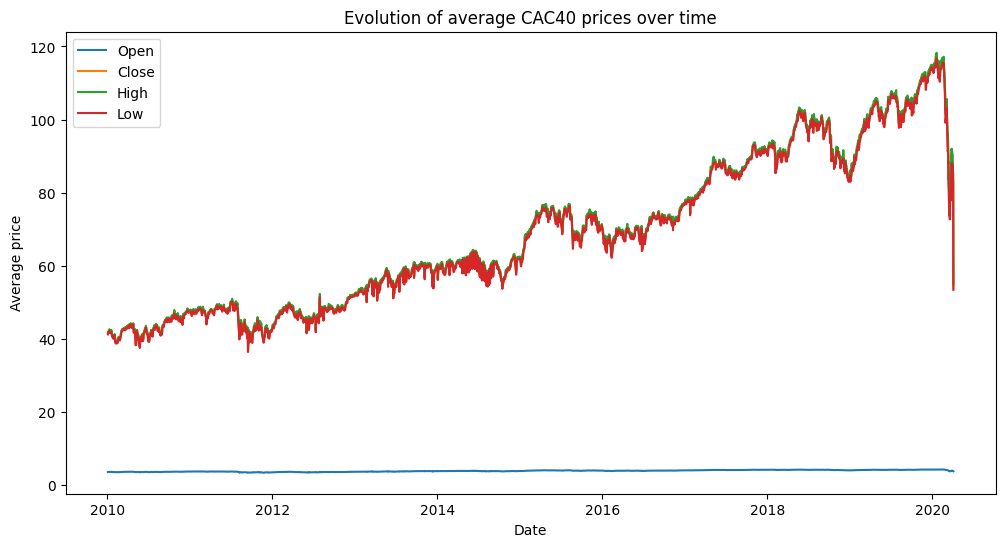

In [16]:
# For the entire CAC40 (average price)
cac40 = data.groupby('Date')[['Open_Price', 'Closing_Price', 'Daily_High', 'Daily_Low']].mean()
plt.figure(figsize=(12, 6))
plt.plot(cac40.index, cac40['Open_Price'], label='Open')
plt.plot(cac40.index, cac40['Closing_Price'], label='Close')
plt.plot(cac40.index, cac40['Daily_High'], label='High')
plt.plot(cac40.index, cac40['Daily_Low'], label='Low')
plt.title('Evolution of average CAC40 prices over time')
plt.xlabel('Date')
plt.ylabel('Average price')
plt.legend()
plt.show()

### Volume evolution over time

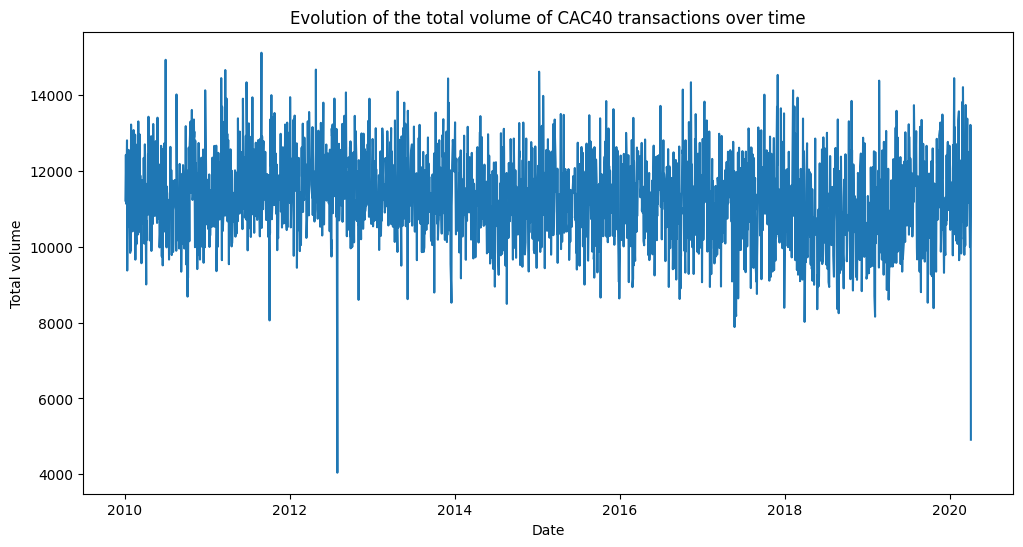

In [17]:
# For the entire CAC40 (total volume)
cac40_volume = data.groupby('Date')['Volume'].sum()
plt.figure(figsize=(12, 6))
plt.plot(cac40_volume.index, cac40_volume)
plt.title('Evolution of the total volume of CAC40 transactions over time')
plt.xlabel('Date')
plt.ylabel('Total volume')
plt.show()

### Comparison of companies performance

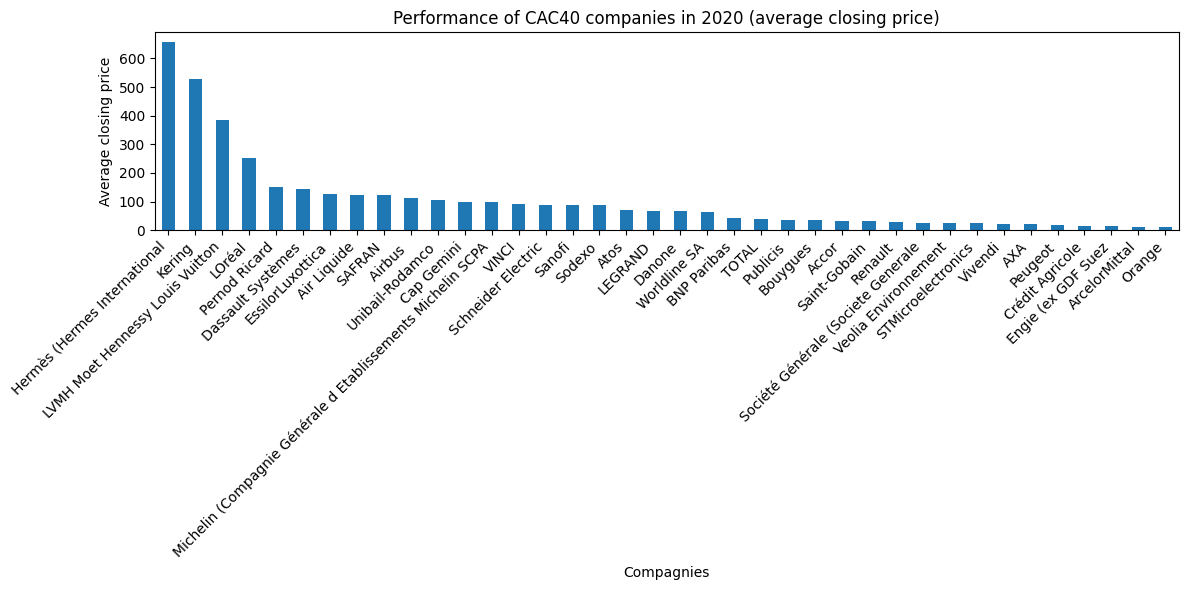

In [18]:
# Bar chart to compare performance over a given period (example: 2020)
data_2020 = data[data['year'] == 2020]
performance_2020 = data_2020.groupby('Compagnie')['Closing_Price'].mean().sort_values(ascending=False)
plt.figure(figsize=(12, 6))
performance_2020.plot(kind='bar')
plt.title('Performance of CAC40 companies in 2020 (average closing price)')
plt.xticks(rotation=45, ha='right')
plt.xlabel('Compagnies')
plt.ylabel('Average closing price')
plt.tight_layout()
plt.show()